# Positional encoding in 3D

The attention mechanism does not know the order of the tokens, so we add a *position vector* to each token embedding:

`input = token_embedding + position_embedding`

Real embeddings have 256 or 768 dimensions. Here we use 3 so we can look at them. The numbers are made up, only the geometry matters.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

SURFACE, INK, INK_2 = '#fcfcfb', '#0b0b0b', '#52514e'

# One color per token (the color follows the token, never its rank)
tokens = {
    'cat': {'vec': np.array([1.0, 2.0, 0.0]), 'color': '#2a78d6'},
    'dog': {'vec': np.array([1.5, 1.6, 0.3]), 'color': '#eb6834'},
    'car': {'vec': np.array([-1.6, 0.4, 1.0]), 'color': '#1baf7a'},
}

# Position vectors: one per position, shared by every token
positions = np.array([
    [0.0, 0.0, 0.0],
    [0.4, -0.3, 0.5],
    [0.7, 0.4, 1.0],
    [0.2, 0.8, 1.5],
])


def new_axes(title, elev=22, azim=-58):
    fig = plt.figure(figsize=(7.5, 6), facecolor=SURFACE)
    ax = fig.add_subplot(projection='3d', facecolor=SURFACE)
    ax.set_xlim(-2.2, 3); ax.set_ylim(-0.5, 3.2); ax.set_zlim(-0.3, 2.2)
    ax.set_xlabel('dim 1', color=INK_2); ax.set_ylabel('dim 2', color=INK_2)
    ax.set_zlabel('dim 3', color=INK_2)
    ax.tick_params(colors=INK_2, labelsize=8)
    ax.view_init(elev=elev, azim=azim)
    ax.set_title(title, color=INK, loc='left')
    return fig, ax

## 1. Token embeddings only

Each token is an arrow from the origin. `cat` and `dog` point to a similar region because their meaning is similar. Nothing here knows *where* in the sentence a token is.

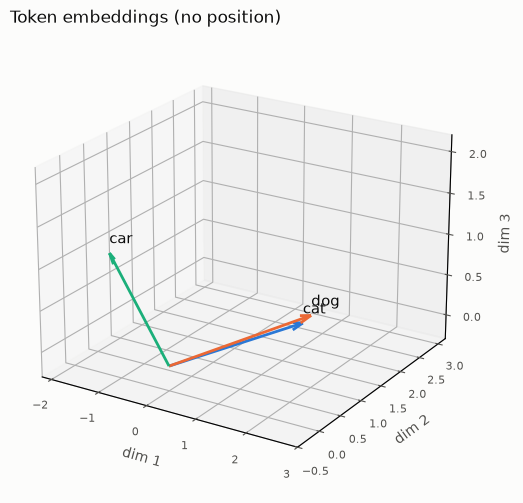

In [2]:
fig, ax = new_axes('Token embeddings (no position)')
for name, tok in tokens.items():
    x, y, z = tok['vec']
    ax.quiver(0, 0, 0, x, y, z, color=tok['color'], arrow_length_ratio=0.08, linewidth=2)
    ax.text(x, y, z + 0.12, name, color=INK, fontsize=11)
plt.show()

## 2. Token + position

Adding the position vector moves the tip of each arrow. The same token in positions 0, 1, 2, 3 lands on 4 different points, connected here by a line. Every token receives the *same* shift for the same position, so the shape of each path is identical.

The shift is small compared to the distance between tokens: the word keeps its region (its meaning) and the position only moves it inside that region.

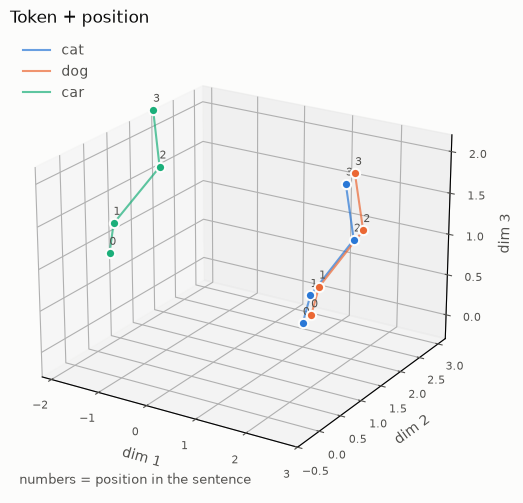

In [3]:
fig, ax = new_axes('Token + position')
for name, tok in tokens.items():
    pts = tok['vec'] + positions
    ax.plot(*pts.T, color=tok['color'], linewidth=1.5, alpha=0.7, label=name)
    ax.scatter(*pts.T, color=tok['color'], s=45, edgecolor=SURFACE, linewidth=1.5, depthshade=False)
    for k, (x, y, z) in enumerate(pts):
        ax.text(x, y, z + 0.1, str(k), color=INK_2, fontsize=8)
ax.legend(loc='upper left', frameon=False, labelcolor=INK_2)
ax.text2D(0.02, 0.02, 'numbers = position in the sentence', transform=ax.transAxes, color=INK_2, fontsize=9)
plt.show()

## 3. One token, four positions, up close

The faint arrow is the original `cat`. The dots are `cat + position_k`. The attention layers now receive 4 slightly different vectors, so they can tell the first `cat` from the third one.

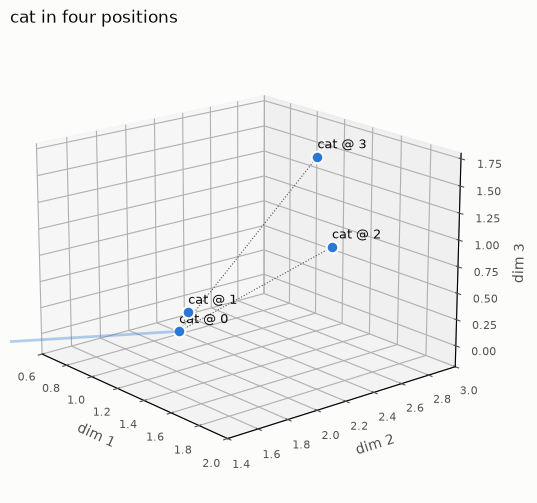

In [4]:
name, tok = 'cat', tokens['cat']
fig, ax = new_axes('cat in four positions', elev=18, azim=-40)
ax.set_xlim(0.6, 2); ax.set_ylim(1.4, 3); ax.set_zlim(-0.2, 1.8)
x, y, z = tok['vec']
ax.quiver(0, 0, 0, x, y, z, color=tok['color'], alpha=0.35, arrow_length_ratio=0.0, linewidth=2)
pts = tok['vec'] + positions
for k, p in enumerate(pts):
    ax.plot(*zip(tok['vec'], p), color=INK_2, linewidth=0.8, linestyle=':')
    ax.scatter(*p, color=tok['color'], s=70, edgecolor=SURFACE, linewidth=1.5, depthshade=False)
    ax.text(p[0], p[1], p[2] + 0.08, f'cat @ {k}', color=INK, fontsize=9)
plt.show()

## In PyTorch

The numbers above are invented, but the operation is the same one GPT-2 uses:

```python
token_emb = token_embedding_layer(inputs)                      # [batch, seq_len, emb_dim]
pos_emb = pos_embedding_layer(torch.arange(seq_len))          # [seq_len, emb_dim]
x = token_emb + pos_emb                                        # broadcast over the batch
```

GPT-2 *learns* `pos_embedding_layer` (an `Embedding(context_length, emb_dim)`), while the original Transformer used fixed sin/cos values. Either way the vector is added, not looked up separately.